In [49]:
import tensorflow as tf
from tensorflow.keras import datasets


In [50]:
(x_train, y_train), (x_test, y_test) = datasets.mnist.load_data()

In [51]:
type(x_train)

x_train.ndim

x_train.shape, x_test.shape

((60000, 28, 28), (10000, 28, 28))

In [52]:
x_train_vector = x_train.reshape(-1, 784)
x_test_vector = x_test.reshape(-1, 784)

x_train_vector = x_train_vector.astype("float32") / 255
x_test_vector = x_test_vector.astype("float32") / 255

x_train_vector.dtype
x_train_vector[x_train_vector > 0]

array([0.01176471, 0.07058824, 0.07058824, ..., 0.75686276, 0.77254903,
       0.5254902 ], dtype=float32)

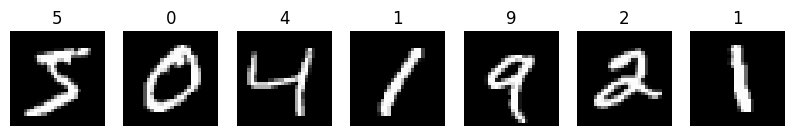

In [53]:
import matplotlib.pyplot as plt

fig, axis = plt.subplots(1, 7, figsize = (10, 5))

for i in range(len(axis)):
    axis[i].imshow(x_train[i], cmap="gray")
    axis[i].set_title(y_train[i])
    axis[i].set_axis_off()

In [54]:
from tensorflow.keras import Sequential, layers

model = Sequential([
    layers.Dense(512, activation="relu", input_shape=(784,)),
    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_4 (Dense)             (None, 512)               401920    
                                                                 
 dense_5 (Dense)             (None, 10)                5130      
                                                                 
Total params: 407,050
Trainable params: 407,050
Non-trainable params: 0
_________________________________________________________________


In [55]:
from tensorflow.keras import optimizers, losses, metrics

model.compile(
    optimizer=optimizers.SGD(),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=[metrics.SparseCategoricalAccuracy()]
)

In [56]:
history = model.fit(x_train_vector, y_train, epochs=50, batch_size=128, validation_split=0.2)

Epoch 1/50
375/375 [==============================] - 2s 4ms/step - loss: 1.2026 - sparse_categorical_accuracy: 0.7412 - val_loss: 0.6680 - val_sparse_categorical_accuracy: 0.8655
Epoch 2/50
375/375 [==============================] - 1s 3ms/step - loss: 0.5832 - sparse_categorical_accuracy: 0.8628 - val_loss: 0.4681 - val_sparse_categorical_accuracy: 0.8866
Epoch 3/50
375/375 [==============================] - 1s 3ms/step - loss: 0.4610 - sparse_categorical_accuracy: 0.8836 - val_loss: 0.3982 - val_sparse_categorical_accuracy: 0.8969
Epoch 4/50
375/375 [==============================] - 1s 3ms/step - loss: 0.4058 - sparse_categorical_accuracy: 0.8931 - val_loss: 0.3607 - val_sparse_categorical_accuracy: 0.9043
Epoch 5/50
375/375 [==============================] - 1s 3ms/step - loss: 0.3726 - sparse_categorical_accuracy: 0.8997 - val_loss: 0.3367 - val_sparse_categorical_accuracy: 0.9086
Epoch 6/50
375/375 [==============================] - 1s 3ms/step - loss: 0.3495 - sparse_categorica

In [57]:
history.history.keys()

dict_keys(['loss', 'sparse_categorical_accuracy', 'val_loss', 'val_sparse_categorical_accuracy'])

<function matplotlib.pyplot.show(close=None, block=None)>

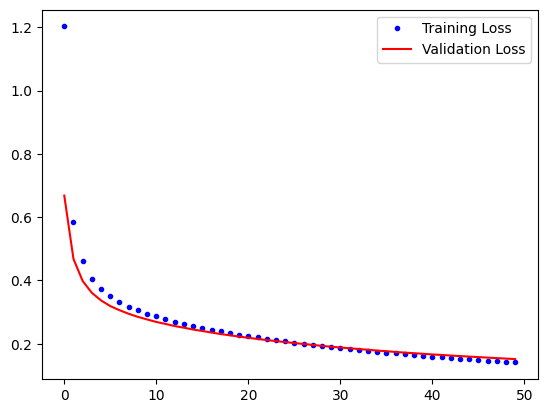

In [58]:
from cProfile import label


loss = history.history["loss"]
val_loss = history.history["val_loss"]

plt.plot(loss, "b.", label="Training Loss")
plt.plot(val_loss, "r", label="Validation Loss")
plt.legend()
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

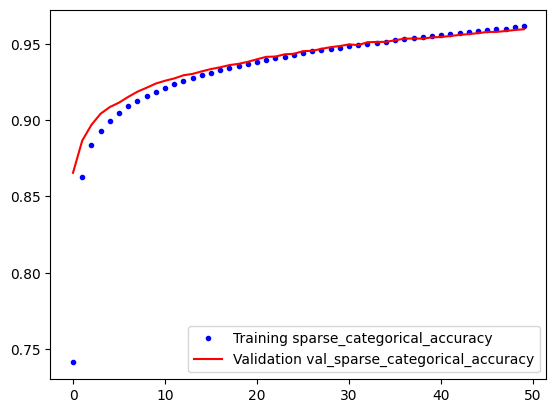

In [59]:
sparse_categorical_accuracy = history.history["sparse_categorical_accuracy"]
val_sparse_categorical_accuracy = history.history["val_sparse_categorical_accuracy"]

plt.plot(sparse_categorical_accuracy, "b.", label="Training sparse_categorical_accuracy")
plt.plot(val_sparse_categorical_accuracy, "r", label="Validation val_sparse_categorical_accuracy")
plt.legend()
plt.show

In [60]:
eval_loss, eval_acc = model.evaluate(x_test_vector, y_test)

print(f"Eval Loss: {(eval_loss * 100):.2f}%")
print(f"Eval ACC: {(eval_acc * 100):.2f}%")

313/313 [==============================] - 1s 2ms/step - loss: 0.1492 - sparse_categorical_accuracy: 0.9572
Eval Loss: 14.92%
Eval ACC: 95.72%


In [61]:
y_pred = model.predict(x_test_vector)

313/313 [==============================] - 0s 1ms/step


In [62]:
y_pred

array([[4.1532548e-05, 3.2661475e-07, 8.4624212e-04, ..., 9.9634463e-01,
        1.9853405e-05, 2.6690759e-04],
       [3.2490524e-04, 4.9979315e-04, 9.9140137e-01, ..., 9.7873771e-09,
        2.1532121e-04, 1.5851372e-08],
       [3.0706935e-05, 9.8043352e-01, 5.7473304e-03, ..., 4.9840691e-03,
        2.9118056e-03, 2.4358378e-04],
       ...,
       [2.6567957e-07, 8.2183533e-08, 5.4866523e-06, ..., 1.5280876e-04,
        1.1270571e-03, 4.3291170e-03],
       [2.5359366e-05, 3.5751491e-05, 8.9086243e-06, ..., 1.7218322e-06,
        2.3008876e-03, 3.8142161e-06],
       [1.8954921e-05, 6.1682299e-09, 1.0235330e-04, ..., 4.0180330e-09,
        7.4848134e-07, 1.2760110e-07]], dtype=float32)

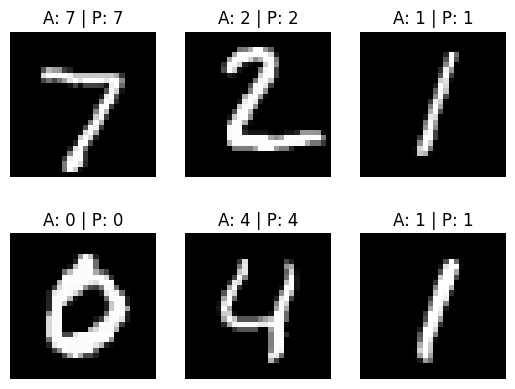

In [63]:
y_pred = y_pred.argmax(axis=1)

fig, axis = plt.subplots(2, 3)

for i, ax in enumerate(axis.flatten()):
    ax.imshow(x_test[i], cmap="gray")
    ax.set_title(f"A: {y_test[i]} | P: {y_pred[i]}")
    ax.set_axis_off()

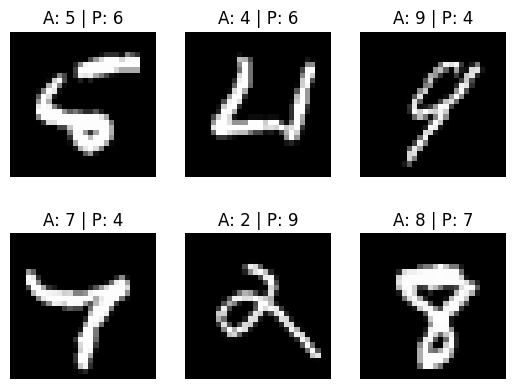

In [65]:
y_pred_loss = []

for i in range(len(y_test)):
    if y_test[i] != y_pred[i]:
        y_pred_loss.append(i)

fig, axis = plt.subplots(2, 3)

for i, ax in enumerate(axis.flatten()):
    ax.imshow(x_test[y_pred_loss[i]], cmap="gray")
    ax.set_title(f"A: {y_test[y_pred_loss[i]]} | P: {y_pred[y_pred_loss[i]]}")
    ax.set_axis_off()

In [66]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.99      0.97       980
           1       0.98      0.99      0.98      1135
           2       0.96      0.96      0.96      1032
           3       0.95      0.95      0.95      1010
           4       0.95      0.96      0.95       982
           5       0.96      0.94      0.95       892
           6       0.95      0.97      0.96       958
           7       0.95      0.95      0.95      1028
           8       0.95      0.94      0.95       974
           9       0.95      0.93      0.94      1009

    accuracy                           0.96     10000
   macro avg       0.96      0.96      0.96     10000
weighted avg       0.96      0.96      0.96     10000



In [67]:
model.save("0_MLP_MNIST.h5")